# Email Spam Classification with NumPy

This notebook compares two classifiers for identifying **spam** (`1`) and **ham** / non-spam (`0`) email:

1. A linear model trained with gradient descent on squared error.
2. Logistic regression trained with gradient descent and binary cross-entropy loss.

The workflow uses a training set to fit models, a validation set to choose hyperparameters and decision thresholds, and a held-out test set for the final evaluation. The test set is not used to tune either model.

**Before running:** place `spam_ham_dataset.csv` in the same folder as this notebook. The file must contain `text` and `label_num` columns.

## 1. Import libraries

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import hstack
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

## 2. Load and inspect the dataset

In [14]:
# Each row should contain an email's text and its numeric label.
df = pd.read_csv("spam_ham_dataset.csv")

required_columns = {"text", "label_num"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

# Remove rows with missing text or labels so vectorization and training are well-defined.
df = df.dropna(subset=["text", "label_num"]).copy()
df["label_num"] = df["label_num"].astype(int)
if not set(df["label_num"].unique()).issubset({0, 1}):
    raise ValueError("label_num must use 0 for ham and 1 for spam.")

print(df.head())
print("\nDataset shape:", df.shape)
print("\nClass counts (0 = ham, 1 = spam):")
print(df["label_num"].value_counts().sort_index())

   Unnamed: 0 label                                               text  \
0         605   ham  Subject: enron methanol ; meter # : 988291\r\n...   
1        2349   ham  Subject: hpl nom for january 9 , 2001\r\n( see...   
2        3624   ham  Subject: neon retreat\r\nho ho ho , we ' re ar...   
3        4685  spam  Subject: photoshop , windows , office . cheap ...   
4        2030   ham  Subject: re : indian springs\r\nthis deal is t...   

   label_num  
0          0  
1          0  
2          0  
3          1  
4          0  

Dataset shape: (5171, 4)

Class counts (0 = ham, 1 = spam):
label_num
0    3672
1    1499
Name: count, dtype: int64


## 3. Split into training, validation, and test sets

In [15]:
# Keep labels stratified so the class proportions are similar across splits.
X = df["text"].astype(str)
y = df["label_num"].astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train:      {len(X_train)} emails")
print(f"Validation: {len(X_val)} emails")
print(f"Test:       {len(X_test)} emails")

Train:      4136 emails
Validation: 517 emails
Test:       518 emails


## 4. Convert email text into numeric features

In [16]:
# CountVectorizer builds a bag-of-words feature for each token.
# Fit it on training text only to avoid leaking validation/test vocabulary information.
vectorizer = CountVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_val_vec = vectorizer.transform(X_val)
X_test_vec = vectorizer.transform(X_test)

print("Training feature matrix:", X_train_vec.shape)
print("Feature matrix type:", type(X_train_vec))

Training feature matrix: (4136, 43788)
Feature matrix type: <class 'scipy.sparse._csr.csr_matrix'>


### Why the standardization example is omitted

The original notebook included a commented-out attempt to standardize the sparse count matrix. This notebook does not use that code: centering a sparse bag-of-words matrix can make it dense and use a large amount of memory. Both models below therefore use the same count features for a fair comparison.

## 5. Shared classifier and evaluation helpers

In [17]:
class NumpyClassifier:
    """Base class for the NumPy-based classifiers in this notebook."""
    pass


def accuracy(y_pred, y_true):
    """Return the fraction of labels predicted correctly."""
    y_pred = np.asarray(y_pred).reshape(-1)
    y_true = np.asarray(y_true).reshape(-1)
    if y_pred.shape != y_true.shape:
        raise ValueError("y_pred and y_true must have the same shape")
    return float(np.mean(y_pred == y_true))


def binary_classification_metrics(y_true, y_pred):
    """Return confusion counts and precision, recall, and F1 for spam=1."""
    y_true = np.asarray(y_true, dtype=int).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=int).reshape(-1)
    if y_pred.shape != y_true.shape:
        raise ValueError("y_true and y_pred must have the same shape")

    tp = int(np.sum((y_pred == 1) & (y_true == 1)))
    fp = int(np.sum((y_pred == 1) & (y_true == 0)))
    fn = int(np.sum((y_pred == 0) & (y_true == 1)))
    tn = int(np.sum((y_pred == 0) & (y_true == 0)))

    # Return zero if a denominator is zero, rather than dividing by zero.
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = (2 * precision * recall / (precision + recall)
          if (precision + recall) else 0.0)
    return tp, fp, fn, tn, precision, recall, f1


def print_metrics(y_true, y_pred, title):
    """Print the main evaluation metrics for a model."""
    tp, fp, fn, tn, precision, recall, f1 = binary_classification_metrics(y_true, y_pred)
    print(title)
    print(f"Accuracy:  {accuracy(y_pred, y_true):.4f}")
    print(f"TP: {tp} | FP: {fp} | FN: {fn} | TN: {tn}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 score:  {f1:.4f}")
    return tp, fp, fn, tn, precision, recall, f1


def plot_confusion_matrix(y_true, y_pred, title):
    """Plot a confusion matrix with actual labels as rows and predictions as columns."""
    tp, fp, fn, tn, *_ = binary_classification_metrics(y_true, y_pred)
    cm = np.array([[tn, fp], [fn, tp]])

    fig, ax = plt.subplots(figsize=(5, 4))
    image = ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1], labels=["Ham", "Spam"])
    ax.set_yticks([0, 1], labels=["Ham", "Spam"])
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.set_title(title)

    threshold = cm.max() / 2 if cm.size and cm.max() else 0
    for row in range(2):
        for col in range(2):
            ax.text(col, row, str(cm[row, col]), ha="center", va="center",
                    color="white" if cm[row, col] > threshold else "black")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout()
    plt.show()

## 6. Linear classifier

The linear classifier adds a bias term and learns weights using batch gradient descent on squared error. Its output is a score, which is converted into a ham/spam prediction using a decision threshold.

In [ ]:
class NumpyLinRegClass(NumpyClassifier):
    """Linear score model trained with squared-error gradient descent."""

    def __init__(self):
        self.weights = None
        self.training_loss = []
        self.val_loss = []
        self.training_acc = []
        self.val_acc = []

    @staticmethod
    def _add_bias(X):
        bias = np.ones((X.shape[0], 1), dtype=float)
        return hstack([bias, X], format="csr")

    def fit(self, X, y, X_val, y_val, lr=1e-4, epochs=1000):
        y = np.asarray(y, dtype=float).reshape(-1)
        y_val = np.asarray(y_val, dtype=float).reshape(-1)

        X_bias = self._add_bias(X)
        X_val_bias = self._add_bias(X_val)

        n_samples, n_features = X_bias.shape

        self.weights = np.zeros(n_features, dtype=float)
        self.training_loss = []
        self.training_acc = []
        self.val_loss = []
        self.val_acc = []
        self.epoch = 0

        for epoch in range(epochs):
        # Calculate predictions using current weights.
            predictions = np.asarray(X_bias @ self.weights).reshape(-1)

            # Calculate gradient and update weights.
            error = predictions - y
            # Gradient of half the mean squared error (1/2 * MSE).
            # The factor of 1/2 cancels the factor of 2 when differentiating.
            # We still report ordinary MSE in the training and validation plots.
            gradient = np.asarray(X_bias.T @ error).reshape(-1) / n_samples
            self.weights -= lr * gradient

            # Calculate scores after updating weights.
            train_scores = np.asarray(X_bias @ self.weights).reshape(-1)
            val_scores = np.asarray(X_val_bias @ self.weights).reshape(-1)

            # Calculate training and validation loss (MSE).
            train_loss = float(np.mean((train_scores - y) ** 2))
            validation_loss = float(np.mean((val_scores - y_val) ** 2))

            # Convert scores into class predictions.
            train_pred = (train_scores >= 0.5).astype(int)
            val_pred = (val_scores >= 0.5).astype(int)

            # Calculate training and validation accuracy.
            train_acc = accuracy(train_pred, y)
            validation_acc = accuracy(val_pred, y_val)

            # Record all four metrics after every epoch.
            self.training_loss.append(train_loss)
            self.training_acc.append(train_acc)
            self.val_loss.append(validation_loss)
            self.val_acc.append(validation_acc)

            self.epoch = epoch + 1

        return self
    def decision_function(self, X):
        if self.weights is None:
            raise ValueError("Call fit() before making predictions.")
        return np.asarray(self._add_bias(X) @ self.weights).reshape(-1)

    def predict(self, X, threshold=0.5):
        return (self.decision_function(X) >= threshold).astype(int)

### Establish a baseline

In [36]:
# Baseline: train with a fixed learning rate and epoch count before tuning.
linear_baseline = NumpyLinRegClass().fit(X_train_vec, y_train, X_val_vec, y_val, lr=1e-4, epochs=1000)
baseline_train_pred = linear_baseline.predict(X_train_vec)
print(f"Baseline training accuracy: {accuracy(baseline_train_pred, y_train):.4f}")

Baseline training accuracy: 0.7333


### Tune the linear model

In [38]:
# Select hyperparameters using validation accuracy, not test accuracy.
linear_learning_rates = [1e-5, 1e-4, 5e-4]
linear_epochs_list = [500, 1000, 2000]

best_linear_lr = None
best_linear_epochs = None
best_linear_val_accuracy = -1.0

for lr in linear_learning_rates:
    for epochs in linear_epochs_list:
        candidate = NumpyLinRegClass().fit(X_train_vec, y_train, X_val_vec, y_val, lr=lr, epochs=epochs)
        val_pred = candidate.predict(X_val_vec)
        val_acc = accuracy(val_pred, y_val)
        print(f"lr={lr:g}, epochs={epochs}, validation accuracy={val_acc:.4f}")

        if val_acc > best_linear_val_accuracy:
            best_linear_val_accuracy = val_acc
            best_linear_lr = lr
            best_linear_epochs = epochs

print("\nSelected linear-model settings")
print("Learning rate:", best_linear_lr)
print("Epochs:", best_linear_epochs)
print(f"Validation accuracy: {best_linear_val_accuracy:.4f}")

# Refit one model with the selected settings before threshold selection.
linear_model = NumpyLinRegClass().fit(
    X_train_vec, y_train, X_val_vec, y_val, lr=best_linear_lr, epochs=best_linear_epochs
)

lr=1e-05, epochs=500, validation accuracy=0.7137
lr=1e-05, epochs=1000, validation accuracy=0.7099
lr=1e-05, epochs=2000, validation accuracy=0.7253
lr=0.0001, epochs=500, validation accuracy=0.7273
lr=0.0001, epochs=1000, validation accuracy=0.7273
lr=0.0001, epochs=2000, validation accuracy=0.7350
lr=0.0005, epochs=500, validation accuracy=0.7369
lr=0.0005, epochs=1000, validation accuracy=0.7524
lr=0.0005, epochs=2000, validation accuracy=0.7930

Selected linear-model settings
Learning rate: 0.0005
Epochs: 2000
Validation accuracy: 0.7930


### Choose a decision threshold

In [39]:
# Threshold selection is a validation step. The test set remains untouched.
threshold_candidates = np.arange(0.10, 1.00, 0.05)
best_linear_threshold = 0.5
best_linear_threshold_accuracy = -1.0

for threshold in threshold_candidates:
    val_pred = linear_model.predict(X_val_vec, threshold=threshold)
    val_acc = accuracy(val_pred, y_val)
    print(f"threshold={threshold:.2f}, validation accuracy={val_acc:.4f}")
    if val_acc > best_linear_threshold_accuracy:
        best_linear_threshold_accuracy = val_acc
        best_linear_threshold = threshold

print(f"\nSelected threshold: {best_linear_threshold:.2f}")
print(f"Validation accuracy at selected threshold: {best_linear_threshold_accuracy:.4f}")

threshold=0.10, validation accuracy=0.5609
threshold=0.15, validation accuracy=0.7369
threshold=0.20, validation accuracy=0.8511
threshold=0.25, validation accuracy=0.8704
threshold=0.30, validation accuracy=0.8743
threshold=0.35, validation accuracy=0.8472
threshold=0.40, validation accuracy=0.8395
threshold=0.45, validation accuracy=0.8162
threshold=0.50, validation accuracy=0.7930
threshold=0.55, validation accuracy=0.7814
threshold=0.60, validation accuracy=0.7718
threshold=0.65, validation accuracy=0.7602
threshold=0.70, validation accuracy=0.7563
threshold=0.75, validation accuracy=0.7408
threshold=0.80, validation accuracy=0.7389
threshold=0.85, validation accuracy=0.7408
threshold=0.90, validation accuracy=0.7408
threshold=0.95, validation accuracy=0.7389

Selected threshold: 0.30
Validation accuracy at selected threshold: 0.8743


### Linear classifier: training and validation loss

The curves show mean squared error (MSE) after each epoch for the selected linear model. Validation data is used only to measure performance, not to update weights.

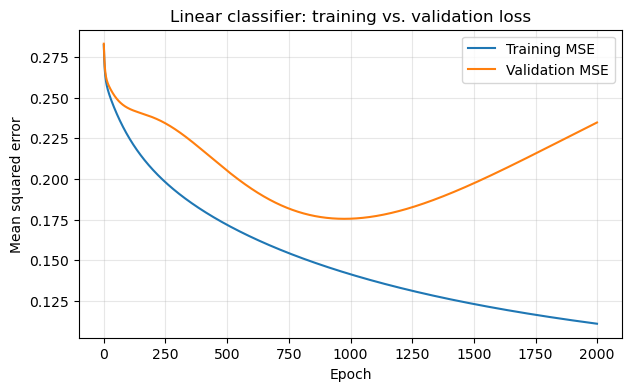

In [40]:
plt.figure(figsize=(7, 4))
plt.plot(linear_model.training_loss, label="Training MSE")
plt.plot(linear_model.val_loss, label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("Linear classifier: training vs. validation loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Linear classifier: training and validation accuracy

The training and validation accuracy curves use a fixed classification threshold of **0.5** throughout training. This allows us to compare how classification performance changes across epochs.

However, the final linear classifier uses a threshold selected on the validation set (**0.30** in this run). Therefore, the accuracy shown in these curves may differ from the final threshold-tuned validation accuracy.

The validation set is used only for evaluation and model selection, not for updating the model weights.

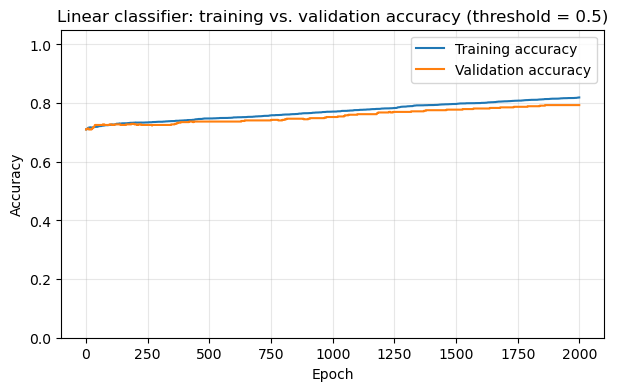

In [41]:
plt.figure(figsize=(7, 4))
plt.plot(linear_model.training_acc, label="Training accuracy")
plt.plot(linear_model.val_acc, label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.title("Linear classifier: training vs. validation accuracy (threshold = 0.5)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Final linear-model test evaluation

Linear classifier — test set
Accuracy:  0.8977
TP: 116 | FP: 19 | FN: 34 | TN: 349
Precision: 0.8593
Recall:    0.7733
F1 score:  0.8140


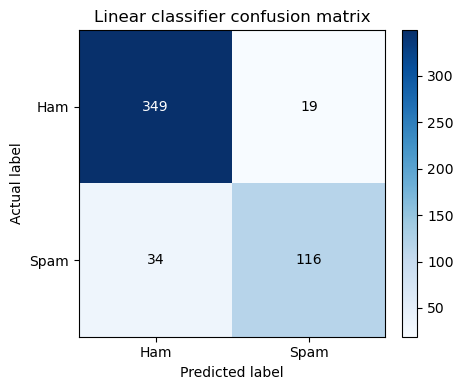

In [42]:
# Evaluate on the test set only after model settings and threshold have been selected.
linear_test_pred = linear_model.predict(X_test_vec, threshold=best_linear_threshold)
print_metrics(y_test, linear_test_pred, "Linear classifier — test set")
plot_confusion_matrix(y_test, linear_test_pred, "Linear classifier confusion matrix")

## 7. Logistic regression

Logistic regression passes a linear score through the sigmoid function to produce a probability between 0 and 1. The model is trained using binary cross-entropy loss. During training it records both training and validation loss/accuracy so the learning process can be inspected.

In [ ]:
def sigmoid(z):
    """Numerically safer sigmoid for scalar or array input."""
    z = np.clip(np.asarray(z, dtype=float), -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


class NumpyLogReg(NumpyClassifier):
    """Logistic regression with batch gradient descent and validation early stopping."""

    def __init__(self, bias=1.0):
        self.bias = float(bias)
        self.weights = None
        self.epoch = 0
        self.training_loss = []
        self.training_acc = []
        self.val_loss = []
        self.val_acc = []

    def _add_bias(self, X):
        bias_column = np.full((X.shape[0], 1), self.bias, dtype=float)
        return hstack([bias_column, X], format="csr")

    def predict_probability(self, X):
        if self.weights is None:
            raise ValueError("Call fit() before making predictions.")
        scores = np.asarray(self._add_bias(X) @ self.weights).reshape(-1)
        return sigmoid(scores)

    def predict(self, X, threshold=0.5):
        return (self.predict_probability(X) >= threshold).astype(int)

    def loss(self, X, y_true):
        y_true = np.asarray(y_true, dtype=float).reshape(-1)
        probabilities = np.clip(self.predict_probability(X), 1e-15, 1 - 1e-15)
        return float(-np.mean(
            y_true * np.log(probabilities)
            + (1 - y_true) * np.log(1 - probabilities)
        ))

    def fit(self, X, y, X_val, y_val, lr=1e-3, epochs=1000,
            tols=1e-4, no_update=5):
        y = np.asarray(y, dtype=float).reshape(-1)
        y_val = np.asarray(y_val, dtype=int).reshape(-1)
        X_bias = self._add_bias(X)
        n_samples, n_features = X_bias.shape
        self.weights = np.zeros(n_features, dtype=float)
        self.training_loss = []
        self.training_acc = []
        self.val_loss = []
        self.val_acc = []
        self.epoch = 0

        best_val_loss = float("inf")
        best_weights = self.weights.copy()
        epochs_without_improvement = 0

        for epoch in range(epochs):
            # Compute probabilities with current weights, then update weights.
            probabilities = self.predict_probability(X)
            error = probabilities - y
            gradient = np.asarray(X_bias.T @ error).reshape(-1) / n_samples
            self.weights -= lr * gradient

            # Record metrics after the update. Validation loss must use X_val/y_val.
            train_loss = self.loss(X, y)
            validation_loss = self.loss(X_val, y_val)
            train_acc = accuracy(self.predict(X), y)
            validation_acc = accuracy(self.predict(X_val), y_val)

            self.training_loss.append(train_loss)
            self.training_acc.append(train_acc)
            self.val_loss.append(validation_loss)
            self.val_acc.append(validation_acc)
            self.epoch = epoch + 1

            if best_val_loss - validation_loss > tols:
                best_val_loss = validation_loss
                best_weights = self.weights.copy()
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1

            if epochs_without_improvement >= no_update:
                break

        # Keep the weights from the best validation-loss epoch, not the final epoch.
        self.weights = best_weights
        return self

### Tune learning rate and early-stopping tolerance

In [12]:
# The grid is intentionally modest because each fit uses the full training set.
logreg_learning_rates = [1e-4, 1e-3, 1e-2]
logreg_tolerances = [1e-5, 1e-4, 1e-3]

best_logreg_val_accuracy = -1.0
best_logreg_lr = None
best_logreg_tolerance = None
best_logreg_model = None
logreg_search_results = []

for lr in logreg_learning_rates:
    for tolerance in logreg_tolerances:
        candidate = NumpyLogReg().fit(
            X_train_vec, y_train, X_val_vec, y_val,
            lr=lr, epochs=1000, tols=tolerance, no_update=5
        )
        val_pred = candidate.predict(X_val_vec)
        val_acc = accuracy(val_pred, y_val)
        logreg_search_results.append((lr, tolerance, val_acc, candidate.epoch))
        print(f"lr={lr:g}, tolerance={tolerance:g}, "
              f"validation accuracy={val_acc:.4f}, epochs={candidate.epoch}")

        if val_acc > best_logreg_val_accuracy:
            best_logreg_val_accuracy = val_acc
            best_logreg_lr = lr
            best_logreg_tolerance = tolerance
            best_logreg_model = candidate

print("\nSelected logistic-regression settings")
print("Learning rate:", best_logreg_lr)
print("Tolerance:", best_logreg_tolerance)
print("Epochs used:", best_logreg_model.epoch)
print(f"Validation accuracy: {best_logreg_val_accuracy:.4f}")

lr=0.0001, tolerance=1e-05, validation accuracy=0.7350, epochs=1000
lr=0.0001, tolerance=0.0001, validation accuracy=0.7350, epochs=1000
lr=0.0001, tolerance=0.001, validation accuracy=0.7099, epochs=183
lr=0.001, tolerance=1e-05, validation accuracy=0.8414, epochs=1000
lr=0.001, tolerance=0.0001, validation accuracy=0.8414, epochs=1000
lr=0.001, tolerance=0.001, validation accuracy=0.8066, epochs=388
lr=0.01, tolerance=1e-05, validation accuracy=0.9400, epochs=1000
lr=0.01, tolerance=0.0001, validation accuracy=0.9400, epochs=1000
lr=0.01, tolerance=0.001, validation accuracy=0.8956, epochs=364

Selected logistic-regression settings
Learning rate: 0.01
Tolerance: 1e-05
Epochs used: 1000
Validation accuracy: 0.9400


### Choose the logistic-regression probability threshold

In [13]:
best_logreg_threshold = 0.5
best_logreg_threshold_accuracy = -1.0

for threshold in threshold_candidates:
    val_pred = best_logreg_model.predict(X_val_vec, threshold=threshold)
    val_acc = accuracy(val_pred, y_val)
    print(f"threshold={threshold:.2f}, validation accuracy={val_acc:.4f}")
    if val_acc > best_logreg_threshold_accuracy:
        best_logreg_threshold_accuracy = val_acc
        best_logreg_threshold = threshold

print(f"\nSelected threshold: {best_logreg_threshold:.2f}")
print(f"Validation accuracy at selected threshold: {best_logreg_threshold_accuracy:.4f}")

threshold=0.10, validation accuracy=0.7408
threshold=0.15, validation accuracy=0.8433
threshold=0.20, validation accuracy=0.8723
threshold=0.25, validation accuracy=0.9033
threshold=0.30, validation accuracy=0.9168
threshold=0.35, validation accuracy=0.9304
threshold=0.40, validation accuracy=0.9458
threshold=0.45, validation accuracy=0.9555
threshold=0.50, validation accuracy=0.9400
threshold=0.55, validation accuracy=0.9091
threshold=0.60, validation accuracy=0.8878
threshold=0.65, validation accuracy=0.8685
threshold=0.70, validation accuracy=0.8375
threshold=0.75, validation accuracy=0.8182
threshold=0.80, validation accuracy=0.8066
threshold=0.85, validation accuracy=0.7814
threshold=0.90, validation accuracy=0.7602
threshold=0.95, validation accuracy=0.7408

Selected threshold: 0.45
Validation accuracy at selected threshold: 0.9555


### Inspect training and validation loss

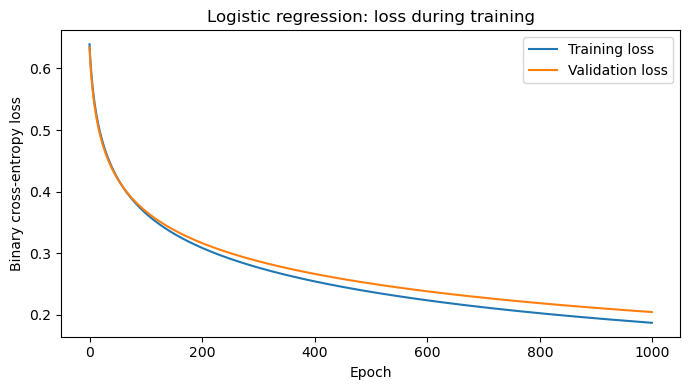

In [14]:
plt.figure(figsize=(7, 4))
plt.plot(best_logreg_model.training_loss, label="Training loss")
plt.plot(best_logreg_model.val_loss, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Logistic regression: loss during training")
plt.legend()
plt.tight_layout()
plt.show()

### Inspect training and validation accuracy

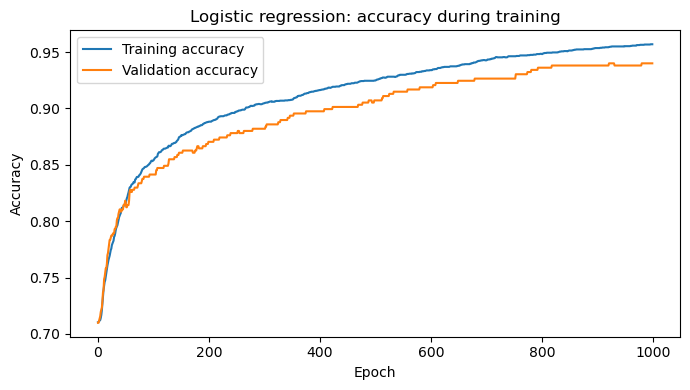

In [15]:
plt.figure(figsize=(7, 4))
plt.plot(best_logreg_model.training_acc, label="Training accuracy")
plt.plot(best_logreg_model.val_acc, label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Logistic regression: accuracy during training")
plt.legend()
plt.tight_layout()
plt.show()

### Final logistic-regression test evaluation

Logistic regression — test set
Accuracy:  0.9653
TP: 143 | FP: 11 | FN: 7 | TN: 357
Precision: 0.9286
Recall:    0.9533
F1 score:  0.9408


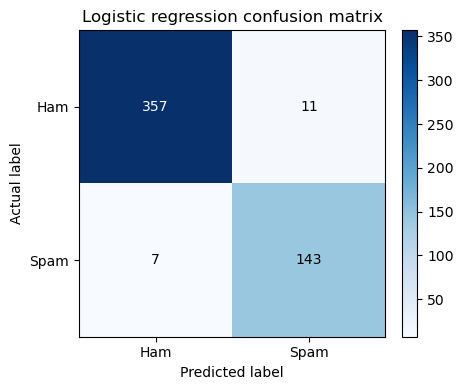

In [16]:
# This is the first and only use of the test set for the logistic model.
logreg_test_pred = best_logreg_model.predict(
    X_test_vec, threshold=best_logreg_threshold
)
print_metrics(y_test, logreg_test_pred, "Logistic regression — test set")
plot_confusion_matrix(y_test, logreg_test_pred, "Logistic regression confusion matrix")

## 8. Compare the two models

In [17]:
linear_test_accuracy = accuracy(linear_test_pred, y_test)
logreg_test_accuracy = accuracy(logreg_test_pred, y_test)

comparison = pd.DataFrame({
    "Model": ["Linear classifier", "Logistic regression"],
    "Selected threshold": [best_linear_threshold, best_logreg_threshold],
    "Test accuracy": [linear_test_accuracy, logreg_test_accuracy],
})
comparison

,Model,Selected threshold,Test accuracy
0,Linear classifier,0.30,0.897683
1,Logistic regression,0.45,0.965251


## Notes for interpreting the results

- **Accuracy** is the share of all messages classified correctly.
- **Precision** answers: of messages predicted as spam, how many were spam?
- **Recall** answers: of all spam messages, how many did the model find?
- **F1 score** combines precision and recall.
- A false positive is a ham email incorrectly flagged as spam; a false negative is spam that the model misses.
- Hyperparameters and thresholds are selected on the validation set. Report the test-set metrics as the final estimate of performance on unseen data.

The best model depends on the objective. If missing spam is especially costly, recall may matter more than accuracy; if incorrectly flagging legitimate email is especially costly, precision may matter more.

## 9. Conclusion

This project compared two NumPy-based classifiers for distinguishing spam from legitimate emails using bag-of-words features.

The linear squared-error classifier achieved a test accuracy of **89.77%**, while logistic regression achieved **96.53%**.

Logistic regression also performed better in terms of precision, recall, and F1 score. In particular, its higher spam recall means that fewer spam emails were incorrectly classified as legitimate.

Although adjusting the decision threshold improved the linear classifier, logistic regression remained the stronger model overall.

These results demonstrate that the choice of loss function matters for classification. The linear classifier minimizes squared error, while logistic regression uses binary cross-entropy, which is specifically suited to binary classification.